In [4]:
from pathlib import Path
import json
from collections import Counter
from PIL import Image
import numpy as np

# ============================================================
# DATASET PATHS
# ============================================================

DATA_ROOT = Path(r"C:\College\Dissertation\Data")

# LEVIR-CC
LEVIR_CC = (
    DATA_ROOT
    / "LEVIR-CC"
    / "Levir-CC-dataset-001"
)

# LEVIR-CD
LEVIR_CD_ROOT_1 = (
    DATA_ROOT
    / "LEVIR-CD"
    / "LEVIR-CD-20261002T144955Z-1-001"
    / "LEVIR-CD"
)

LEVIR_CD_ROOT_2 = (
    DATA_ROOT
    / "LEVIR-CD"
    / "LEVIR-CD-20261002T144955Z-1-002"
    / "LEVIR-CD"
)

print("LEVIR-CC:", LEVIR_CC)
print("Exists:", LEVIR_CC.exists())

print("\nLEVIR-CD part 1:", LEVIR_CD_ROOT_1)
print("Exists:", LEVIR_CD_ROOT_1.exists())

print("\nLEVIR-CD part 2:", LEVIR_CD_ROOT_2)
print("Exists:", LEVIR_CD_ROOT_2.exists())

LEVIR-CC: C:\College\Dissertation\Data\LEVIR-CC\Levir-CC-dataset-001
Exists: True

LEVIR-CD part 1: C:\College\Dissertation\Data\LEVIR-CD\LEVIR-CD-20261002T144955Z-1-001\LEVIR-CD
Exists: True

LEVIR-CD part 2: C:\College\Dissertation\Data\LEVIR-CD\LEVIR-CD-20261002T144955Z-1-002\LEVIR-CD
Exists: True


In [6]:
# ============================================================
# IMAGE FILE HELPER
# ============================================================

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def get_image_files(path):
    """Return only actual image files, ignoring .aux.xml etc."""
    if not path.exists():
        return []

    return sorted([
        f for f in path.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ])


def inspect_folder(path):
    files = get_image_files(path)

    print(f"\n{path}")
    print(f"Image files: {len(files)}")

    if files:
        print("First 5:")
        for f in files[:5]:
            print("   ", f.name)

        print("Last 5:")
        for f in files[-5:]:
            print("   ", f.name)

In [7]:
# ============================================================
# CELL 3 — CORRECT DATASET COUNTS
# ============================================================

print("\n\n########## LEVIR-CC ##########")

for split in ["train", "val", "test"]:
    print(f"\n===== {split.upper()} =====")

    inspect_folder(LEVIR_CC / "images" / split / "A")
    inspect_folder(LEVIR_CC / "images" / split / "B")


print("\n\n########## LEVIR-CD TRAIN / VAL ##########")

for split in ["train", "val"]:
    print(f"\n===== {split.upper()} =====")

    inspect_folder(LEVIR_CD_ROOT_1 / split / "A")
    inspect_folder(LEVIR_CD_ROOT_1 / split / "B")
    inspect_folder(LEVIR_CD_ROOT_1 / split / "label")


print("\n\n########## LEVIR-CD TEST ##########")

inspect_folder(LEVIR_CD_ROOT_2 / "test" / "A")
inspect_folder(LEVIR_CD_ROOT_2 / "test" / "B")
inspect_folder(LEVIR_CD_ROOT_2 / "test" / "label")



########## LEVIR-CC ##########

===== TRAIN =====

C:\College\Dissertation\Data\LEVIR-CC\Levir-CC-dataset-001\images\train\A
Image files: 7590
First 5:
    train_000001.png
    train_000002.png
    train_000003.png
    train_000004.png
    train_000005.png
Last 5:
    train_007586.png
    train_007587.png
    train_007588.png
    train_007589.png
    train_007590.png

C:\College\Dissertation\Data\LEVIR-CC\Levir-CC-dataset-001\images\train\B
Image files: 7590
First 5:
    train_000001.png
    train_000002.png
    train_000003.png
    train_000004.png
    train_000005.png
Last 5:
    train_007586.png
    train_007587.png
    train_007588.png
    train_007589.png
    train_007590.png

===== VAL =====

C:\College\Dissertation\Data\LEVIR-CC\Levir-CC-dataset-001\images\val\A
Image files: 1438
First 5:
    val_000001.png
    val_000002.png
    val_000003.png
    val_000004.png
    val_000005.png
Last 5:
    val_001434.png
    val_001435.png
    val_001436.png
    val_001437.png
    val_0014

In [8]:
# ============================================================
# CELL 4 — VERIFY A/B/LABEL PAIRING
# ============================================================

def image_names(path):
    return {
        f.name
        for f in get_image_files(path)
    }


print("\n########## LEVIR-CC PAIRING ##########")

for split in ["train", "val", "test"]:

    A = image_names(LEVIR_CC / "images" / split / "A")
    B = image_names(LEVIR_CC / "images" / split / "B")

    print(f"\n{split.upper()}")
    print("A:", len(A))
    print("B:", len(B))
    print("A == B:", A == B)

    if A != B:
        print("Only in A:", sorted(A - B)[:10])
        print("Only in B:", sorted(B - A)[:10])


print("\n########## LEVIR-CD TRAIN / VAL ##########")

for split in ["train", "val"]:

    A = image_names(LEVIR_CD_ROOT_1 / split / "A")
    B = image_names(LEVIR_CD_ROOT_1 / split / "B")
    L = image_names(LEVIR_CD_ROOT_1 / split / "label")

    print(f"\n{split.upper()}")
    print("A:", len(A))
    print("B:", len(B))
    print("Label:", len(L))

    print("A == B:", A == B)
    print("A == Label:", A == L)


print("\n########## LEVIR-CD TEST ##########")

A = image_names(LEVIR_CD_ROOT_2 / "test" / "A")
B = image_names(LEVIR_CD_ROOT_2 / "test" / "B")
L = image_names(LEVIR_CD_ROOT_2 / "test" / "label")

print("A:", len(A))
print("B:", len(B))
print("Label:", len(L))

print("A == B:", A == B)
print("A == Label:", A == L)


########## LEVIR-CC PAIRING ##########

TRAIN
A: 7590
B: 7590
A == B: True

VAL
A: 1438
B: 1438
A == B: True

TEST
A: 2135
B: 2135
A == B: True

########## LEVIR-CD TRAIN / VAL ##########

TRAIN
A: 445
B: 445
Label: 445
A == B: True
A == Label: True

VAL
A: 64
B: 64
Label: 64
A == B: True
A == Label: True

########## LEVIR-CD TEST ##########
A: 128
B: 128
Label: 128
A == B: True
A == Label: True


In [9]:
# ============================================================
# CELL 5 — IMAGE DIMENSIONS AND MODES
# ============================================================

def inspect_images(path, n=5):
    files = get_image_files(path)

    print(f"\n{path}")
    print(f"Total images: {len(files)}")

    for f in files[:n]:
        with Image.open(f) as img:
            print(
                f"{f.name:25s} "
                f"size={img.size}, "
                f"mode={img.mode}, "
                f"format={img.format}"
            )


print("########## LEVIR-CC ##########")

inspect_images(
    LEVIR_CC / "images" / "train" / "A"
)

inspect_images(
    LEVIR_CC / "images" / "train" / "B"
)


print("\n\n########## LEVIR-CD ##########")

inspect_images(
    LEVIR_CD_ROOT_1 / "train" / "A"
)

inspect_images(
    LEVIR_CD_ROOT_1 / "train" / "B"
)

inspect_images(
    LEVIR_CD_ROOT_1 / "train" / "label"
)

########## LEVIR-CC ##########

C:\College\Dissertation\Data\LEVIR-CC\Levir-CC-dataset-001\images\train\A
Total images: 7590
train_000001.png          size=(256, 256), mode=RGB, format=PNG
train_000002.png          size=(256, 256), mode=RGB, format=PNG
train_000003.png          size=(256, 256), mode=RGB, format=PNG
train_000004.png          size=(256, 256), mode=RGB, format=PNG
train_000005.png          size=(256, 256), mode=RGB, format=PNG

C:\College\Dissertation\Data\LEVIR-CC\Levir-CC-dataset-001\images\train\B
Total images: 7590
train_000001.png          size=(256, 256), mode=RGB, format=PNG
train_000002.png          size=(256, 256), mode=RGB, format=PNG
train_000003.png          size=(256, 256), mode=RGB, format=PNG
train_000004.png          size=(256, 256), mode=RGB, format=PNG
train_000005.png          size=(256, 256), mode=RGB, format=PNG


########## LEVIR-CD ##########

C:\College\Dissertation\Data\LEVIR-CD\LEVIR-CD-20261002T144955Z-1-001\LEVIR-CD\train\A
Total images: 445
tr

LEVIR-CC TRAIN


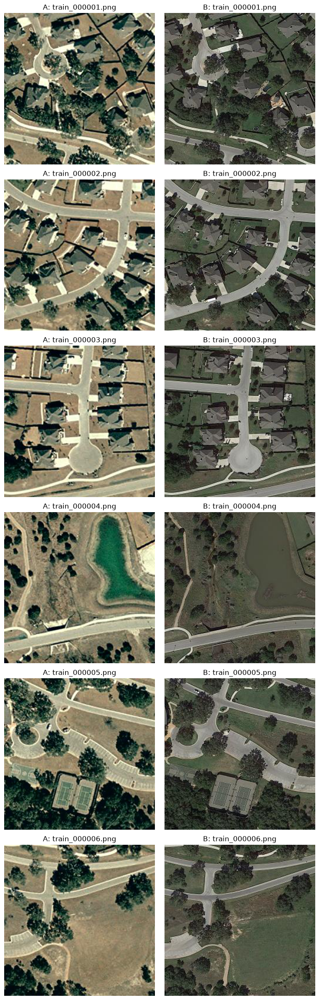

In [12]:
# ============================================================
# CELL 6 — VISUALIZE SAMPLE PAIRS
# ============================================================

import matplotlib.pyplot as plt


def show_pairs(dataset_root, split, n=6, label_folder=None):
    A_path = dataset_root / split / "A"
    B_path = dataset_root / split / "B"

    A_files = get_image_files(A_path)[:n]

    fig, axes = plt.subplots(n, 2, figsize=(8, 4 * n))

    if n == 1:
        axes = np.array([axes])

    for i, a_file in enumerate(A_files):

        b_file = B_path / a_file.name

        with Image.open(a_file) as img_a:
            img_a = np.array(img_a)

        with Image.open(b_file) as img_b:
            img_b = np.array(img_b)

        axes[i, 0].imshow(img_a)
        axes[i, 0].set_title(f"A: {a_file.name}")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(img_b)
        axes[i, 1].set_title(f"B: {a_file.name}")
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()


print("LEVIR-CC TRAIN")
show_pairs(
    LEVIR_CC / "images",
    "train",
    n=6
)

In [11]:
pip install matplotlib

  Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl.metadata (80 kB)
Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl (9.3 MB)
Note: you may need to restart the kernel to use updated packages.


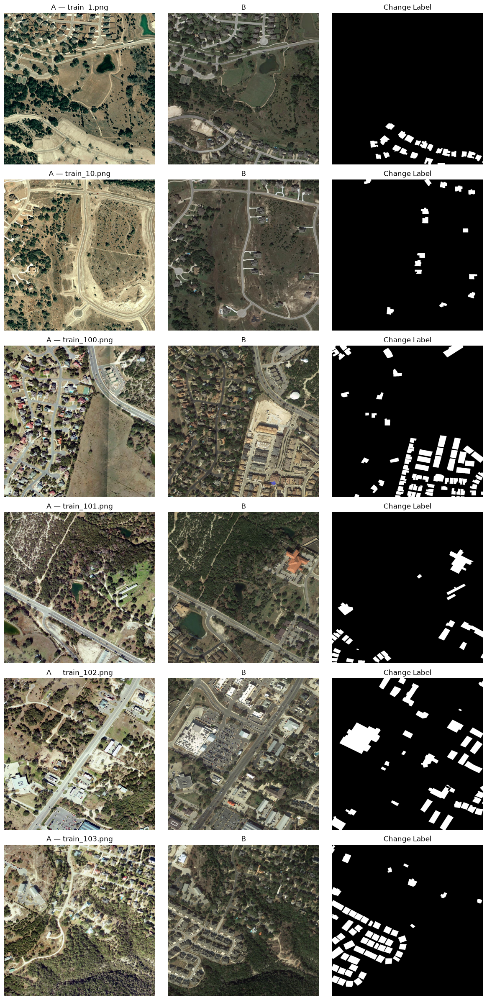

In [13]:
# ============================================================
# CELL 7 — LEVIR-CD A / B / LABEL
# ============================================================

def show_cd_examples(split="train", n=6):

    A_path = (
        LEVIR_CD_ROOT_1 / split / "A"
        if split != "test"
        else LEVIR_CD_ROOT_2 / split / "A"
    )

    B_path = (
        LEVIR_CD_ROOT_1 / split / "B"
        if split != "test"
        else LEVIR_CD_ROOT_2 / split / "B"
    )

    L_path = (
        LEVIR_CD_ROOT_1 / split / "label"
        if split != "test"
        else LEVIR_CD_ROOT_2 / split / "label"
    )

    A_files = get_image_files(A_path)[:n]

    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))

    if n == 1:
        axes = np.array([axes])

    for i, a_file in enumerate(A_files):

        b_file = B_path / a_file.name
        l_file = L_path / a_file.name

        with Image.open(a_file) as img:
            A = np.array(img)

        with Image.open(b_file) as img:
            B = np.array(img)

        with Image.open(l_file) as img:
            L = np.array(img)

        axes[i, 0].imshow(A)
        axes[i, 0].set_title(f"A — {a_file.name}")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(B)
        axes[i, 1].set_title("B")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(L, cmap="gray")
        axes[i, 2].set_title("Change Label")
        axes[i, 2].axis("off")

    plt.tight_layout()
    plt.show()


show_cd_examples("train", n=6)

In [14]:
# ============================================================
# CELL 8 — PERCEPTUAL FINGERPRINTS
# ============================================================

from PIL import Image
import numpy as np


def image_fingerprint(path, size=(32, 32)):
    """
    Convert an image into a compact normalized grayscale
    fingerprint.
    """
    with Image.open(path) as img:
        img = img.convert("L")
        img = img.resize(size, Image.Resampling.LANCZOS)

        arr = np.asarray(img, dtype=np.float32)

    # Normalize brightness/contrast
    arr = (arr - arr.mean()) / (arr.std() + 1e-8)

    return arr.flatten()


# Quick test
cc_example = (
    LEVIR_CC
    / "images"
    / "train"
    / "A"
    / "train_000001.png"
)

cd_example = (
    LEVIR_CD_ROOT_1
    / "train"
    / "A"
    / "train_1.png"
)

fp_cc = image_fingerprint(cc_example)
fp_cd = image_fingerprint(cd_example)

print("Fingerprint size:", fp_cc.shape)
print("CC fingerprint mean:", fp_cc.mean())
print("CD fingerprint mean:", fp_cd.mean())

Fingerprint size: (1024,)
CC fingerprint mean: 3.7252903e-09
CD fingerprint mean: 7.450581e-09


In [15]:
# ============================================================
# CELL 9 — BUILD LEVIR-CC FINGERPRINT DATABASE
# ============================================================

cc_records = []

for split in ["train", "val", "test"]:

    folder = LEVIR_CC / "images" / split / "A"

    for path in get_image_files(folder):

        fp = image_fingerprint(path)

        cc_records.append({
            "split": split,
            "filename": path.name,
            "path": path,
            "fingerprint": fp
        })

print("Total LEVIR-CC fingerprints:", len(cc_records))

Total LEVIR-CC fingerprints: 11163


In [16]:
# ============================================================
# CELL 10 — BUILD LEVIR-CD FINGERPRINT DATABASE
# ============================================================

cd_records = []

for split, root in [
    ("train", LEVIR_CD_ROOT_1),
    ("val", LEVIR_CD_ROOT_1),
    ("test", LEVIR_CD_ROOT_2),
]:

    folder = root / split / "A"

    for path in get_image_files(folder):

        fp = image_fingerprint(path)

        cd_records.append({
            "split": split,
            "filename": path.name,
            "path": path,
            "fingerprint": fp
        })

print("Total LEVIR-CD fingerprints:", len(cd_records))

Total LEVIR-CD fingerprints: 637


In [17]:
# ============================================================
# CELL 11 — CROSS-MATCH CD AGAINST CC
# ============================================================

cc_matrix = np.stack([
    r["fingerprint"]
    for r in cc_records
])

cd_matrix = np.stack([
    r["fingerprint"]
    for r in cd_records
])


# Since fingerprints are normalized,
# correlation similarity is simply a dot product
similarity_matrix = cd_matrix @ cc_matrix.T

best_indices = similarity_matrix.argmax(axis=1)
best_scores = similarity_matrix.max(axis=1)


matches = []

for i, cd_record in enumerate(cd_records):

    j = best_indices[i]

    matches.append({
        "cd_split": cd_record["split"],
        "cd_filename": cd_record["filename"],
        "cc_split": cc_records[j]["split"],
        "cc_filename": cc_records[j]["filename"],
        "similarity": float(best_scores[i])
    })


matches[:10]

[{'cd_split': 'train',
  'cd_filename': 'train_1.png',
  'cc_split': 'train',
  'cc_filename': 'train_003600.png',
  'similarity': 403.59429931640625},
 {'cd_split': 'train',
  'cd_filename': 'train_10.png',
  'cc_split': 'train',
  'cc_filename': 'train_000379.png',
  'similarity': 383.9330749511719},
 {'cd_split': 'train',
  'cd_filename': 'train_100.png',
  'cc_split': 'train',
  'cc_filename': 'train_006336.png',
  'similarity': 223.50634765625},
 {'cd_split': 'train',
  'cd_filename': 'train_101.png',
  'cc_split': 'train',
  'cc_filename': 'train_005218.png',
  'similarity': 474.0296325683594},
 {'cd_split': 'train',
  'cd_filename': 'train_102.png',
  'cc_split': 'train',
  'cc_filename': 'train_001318.png',
  'similarity': 389.0960998535156},
 {'cd_split': 'train',
  'cd_filename': 'train_103.png',
  'cc_split': 'train',
  'cc_filename': 'train_006574.png',
  'similarity': 467.822509765625},
 {'cd_split': 'train',
  'cd_filename': 'train_104.png',
  'cc_split': 'test',
  'cc_fi

In [18]:
# ============================================================
# CELL 12 — MATCH QUALITY
# ============================================================

import pandas as pd

matches_df = pd.DataFrame(matches)

print(matches_df.head(20).to_string(index=False))

print("\nSimilarity statistics:")
print(matches_df["similarity"].describe())

cd_split   cd_filename cc_split      cc_filename  similarity
   train   train_1.png    train train_003600.png  403.594299
   train  train_10.png    train train_000379.png  383.933075
   train train_100.png    train train_006336.png  223.506348
   train train_101.png    train train_005218.png  474.029633
   train train_102.png    train train_001318.png  389.096100
   train train_103.png    train train_006574.png  467.822510
   train train_104.png     test  test_000861.png  325.841187
   train train_105.png     test  test_000957.png  471.605011
   train train_106.png     test  test_001466.png  323.583496
   train train_107.png     test  test_001364.png  302.421112
   train train_108.png      val   val_001322.png  469.029144
   train train_109.png    train train_002512.png  217.310242
   train  train_11.png      val   val_001413.png  360.882507
   train train_110.png    train train_002939.png  493.463287
   train train_111.png    train train_004747.png  323.979523
   train train_112.png  

In [19]:
# Top and bottom matches

print("\n########## HIGHEST SIMILARITY ##########")

print(
    matches_df
    .sort_values("similarity", ascending=False)
    .head(20)
    .to_string(index=False)
)


print("\n########## LOWEST SIMILARITY ##########")

print(
    matches_df
    .sort_values("similarity", ascending=True)
    .head(20)
    .to_string(index=False)
)


########## HIGHEST SIMILARITY ##########
cd_split   cd_filename cc_split      cc_filename  similarity
   train train_428.png     test  test_001340.png  792.633728
     val    val_23.png      val   val_000366.png  733.462769
   train train_119.png    train train_002373.png  715.882751
   train train_166.png      val   val_000696.png  692.805725
   train train_161.png    train train_001896.png  692.727722
   train  train_67.png     test  test_000916.png  686.575012
   train train_216.png     test  test_001011.png  685.172607
    test   test_40.png    train train_004823.png  681.960266
   train train_205.png      val   val_000307.png  679.671021
   train train_204.png    train train_003204.png  676.500183
   train train_141.png      val   val_000901.png  672.601379
   train train_167.png      val   val_000711.png  662.026306
     val    val_44.png    train train_001880.png  661.813843
   train train_318.png    train train_001893.png  661.688660
   train train_286.png    train train_00272

In [20]:
# ============================================================
# CELL 13 — SPLIT ONE LEVIR-CD IMAGE INTO 256x256 TILES
# ============================================================

cd_path = (
    LEVIR_CD_ROOT_1
    / "train"
    / "A"
    / "train_1.png"
)

with Image.open(cd_path) as img:
    cd_img = img.convert("RGB")

print("Original:", cd_img.size)

tile_size = 256

tiles = []

for row in range(4):
    for col in range(4):

        left = col * tile_size
        upper = row * tile_size
        right = left + tile_size
        lower = upper + tile_size

        tile = cd_img.crop(
            (left, upper, right, lower)
        )

        tiles.append(tile)

print("Number of tiles:", len(tiles))
print("Tile size:", tiles[0].size)

Original: (1024, 1024)
Number of tiles: 16
Tile size: (256, 256)


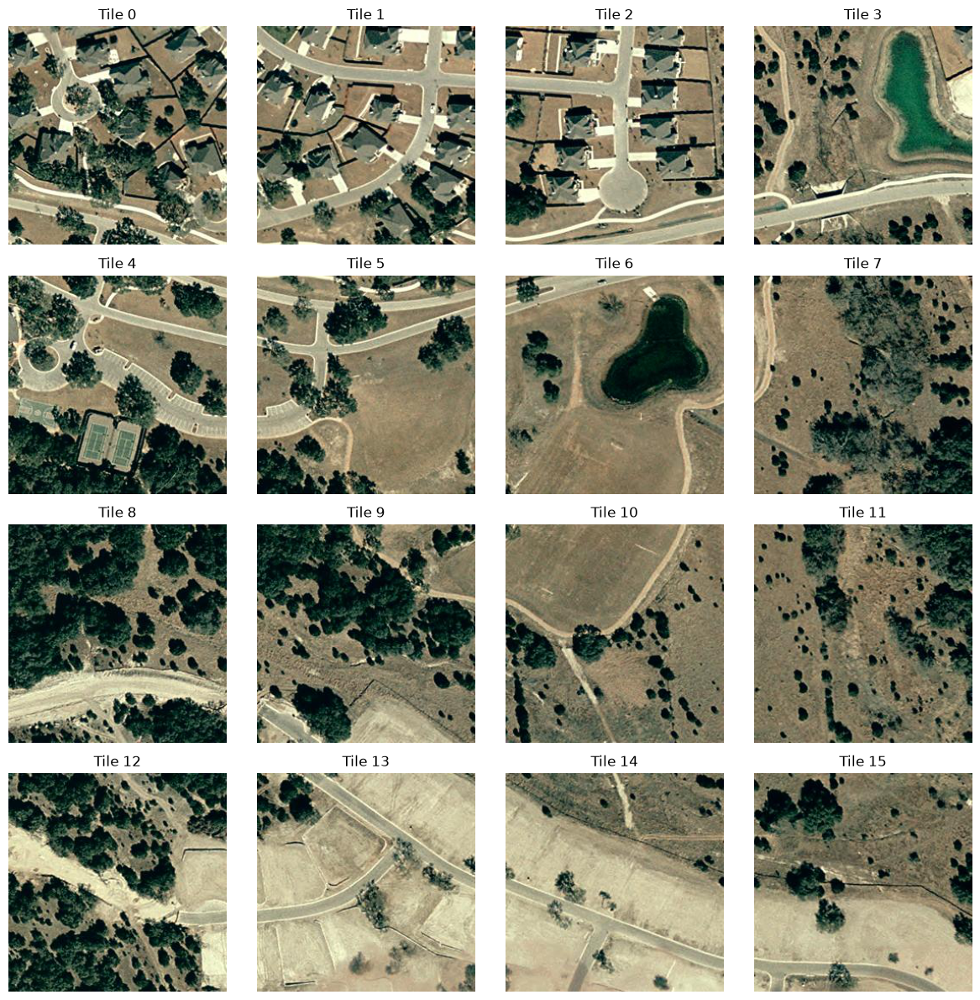

In [21]:
# ============================================================
# CELL 14 — VISUALIZE CD TILES
# ============================================================

fig, axes = plt.subplots(
    4, 4,
    figsize=(12, 12)
)

for i, tile in enumerate(tiles):

    row = i // 4
    col = i % 4

    axes[row, col].imshow(tile)
    axes[row, col].set_title(f"Tile {i}")
    axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [23]:
# ============================================================
# CELL 15 — FAST TILE → LEVIR-CC MATCHING
# ============================================================

import numpy as np
import pandas as pd
from PIL import Image


def small_fingerprint(path_or_image, size=(32, 32)):
    """
    Create a compact normalized grayscale fingerprint.
    """

    if isinstance(path_or_image, Image.Image):
        img = path_or_image
    else:
        img = Image.open(path_or_image)

    img = img.convert("L")
    img = img.resize(size, Image.Resampling.LANCZOS)

    arr = np.asarray(img, dtype=np.float32)

    # Normalize
    arr = (arr - arr.mean()) / (arr.std() + 1e-8)

    return arr.flatten()


# ============================================================
# BUILD COMPACT CC DATABASE
# ============================================================

cc_small = []

for i, record in enumerate(cc_records):

    fp = small_fingerprint(record["path"])

    cc_small.append(fp)

    if (i + 1) % 1000 == 0:
        print(f"Processed {i+1}/{len(cc_records)} CC images")


cc_small = np.stack(cc_small)

print("\nCC fingerprint matrix:", cc_small.shape)

Processed 1000/11163 CC images
Processed 2000/11163 CC images
Processed 3000/11163 CC images
Processed 4000/11163 CC images
Processed 5000/11163 CC images
Processed 6000/11163 CC images
Processed 7000/11163 CC images
Processed 8000/11163 CC images
Processed 9000/11163 CC images
Processed 10000/11163 CC images
Processed 11000/11163 CC images

CC fingerprint matrix: (11163, 1024)


In [24]:
# ============================================================
# CELL 16 — FINGERPRINT CD TILES
# ============================================================

cd_path = (
    LEVIR_CD_ROOT_1
    / "train"
    / "A"
    / "train_1.png"
)

with Image.open(cd_path) as img:
    cd_img = img.convert("RGB")


tile_size = 256

cd_tile_fps = []
tile_images = []

for row in range(4):

    for col in range(4):

        tile = cd_img.crop((
            col * tile_size,
            row * tile_size,
            (col + 1) * tile_size,
            (row + 1) * tile_size
        ))

        tile_images.append(tile)

        fp = small_fingerprint(tile)

        cd_tile_fps.append(fp)


cd_tile_fps = np.stack(cd_tile_fps)

print("CD tile fingerprint matrix:", cd_tile_fps.shape)

CD tile fingerprint matrix: (16, 1024)


In [25]:
# ============================================================
# CELL 17 — MATCH CD TILES AGAINST LEVIR-CC
# ============================================================

similarity = cd_tile_fps @ cc_small.T

best_indices = similarity.argmax(axis=1)
best_scores = similarity.max(axis=1)


results = []

for tile_idx in range(16):

    best_idx = best_indices[tile_idx]

    results.append({
        "tile": tile_idx,
        "row": tile_idx // 4,
        "col": tile_idx % 4,
        "cc_split": cc_records[best_idx]["split"],
        "cc_filename": cc_records[best_idx]["filename"],
        "similarity": float(best_scores[tile_idx])
    })


tile_matches_df = pd.DataFrame(results)

print(tile_matches_df.to_string(index=False))

 tile  row  col cc_split      cc_filename  similarity
    0    0    0    train train_000001.png 1024.000000
    1    0    1    train train_000002.png 1024.000122
    2    0    2    train train_000003.png 1023.999878
    3    0    3    train train_000004.png 1024.000244
    4    1    0    train train_000005.png 1024.000000
    5    1    1    train train_000006.png 1023.999878
    6    1    2    train train_000007.png 1023.999878
    7    1    3    train train_000008.png 1023.999878
    8    2    0    train train_000009.png 1023.999878
    9    2    1    train train_000010.png 1023.999878
   10    2    2    train train_000011.png 1023.999878
   11    2    3    train train_000012.png 1023.999878
   12    3    0    train train_000013.png 1024.000000
   13    3    1    train train_000014.png 1024.000244
   14    3    2    train train_000015.png 1024.000000
   15    3    3    train train_000016.png 1023.999939


In [26]:
# ============================================================
# CELL 18 — EXACT PIXEL VERIFICATION
# ============================================================

import numpy as np
from PIL import Image

cd_path = (
    LEVIR_CD_ROOT_1
    / "train"
    / "A"
    / "train_1.png"
)

with Image.open(cd_path) as img:
    cd_img = np.asarray(img.convert("RGB"))


verification = []

tile_size = 256

for tile_idx in range(16):

    row = tile_idx // 4
    col = tile_idx % 4

    # Extract CD tile
    cd_tile = cd_img[
        row*tile_size:(row+1)*tile_size,
        col*tile_size:(col+1)*tile_size,
        :
    ]

    # Corresponding CC image
    cc_filename = f"train_{tile_idx+1:06d}.png"

    cc_path = (
        LEVIR_CC
        / "images"
        / "train"
        / "A"
        / cc_filename
    )

    with Image.open(cc_path) as img:
        cc_img = np.asarray(img.convert("RGB"))

    diff = np.abs(
        cd_tile.astype(np.int16)
        - cc_img.astype(np.int16)
    )

    verification.append({
        "tile": tile_idx,
        "cc_filename": cc_filename,
        "max_difference": diff.max(),
        "mean_difference": diff.mean(),
        "identical": np.array_equal(cd_tile, cc_img)
    })


verification_df = pd.DataFrame(verification)

print(verification_df.to_string(index=False))

 tile      cc_filename  max_difference  mean_difference  identical
    0 train_000001.png               0              0.0       True
    1 train_000002.png               0              0.0       True
    2 train_000003.png               0              0.0       True
    3 train_000004.png               0              0.0       True
    4 train_000005.png               0              0.0       True
    5 train_000006.png               0              0.0       True
    6 train_000007.png               0              0.0       True
    7 train_000008.png               0              0.0       True
    8 train_000009.png               0              0.0       True
    9 train_000010.png               0              0.0       True
   10 train_000011.png               0              0.0       True
   11 train_000012.png               0              0.0       True
   12 train_000013.png               0              0.0       True
   13 train_000014.png               0              0.0       

In [28]:
# ============================================================
# CELL 19 — VERIFY CD → CC MAPPING
# ============================================================

def verify_cd_to_cc_mapping(cd_index, verbose=True):
    """
    Verify that one LEVIR-CD training image is exactly
    composed of 16 sequential LEVIR-CC training images.
    """

    cd_filename = f"train_{cd_index}.png"

    cd_path = (
        LEVIR_CD_ROOT_1
        / "train"
        / "A"
        / cd_filename
    )

    with Image.open(cd_path) as img:
        cd_img = np.asarray(img.convert("RGB"))

    tile_size = 256

    results = []

    for tile_idx in range(16):

        row = tile_idx // 4
        col = tile_idx % 4

        cd_tile = cd_img[
            row*tile_size:(row+1)*tile_size,
            col*tile_size:(col+1)*tile_size,
            :
        ]

        cc_index = (cd_index - 1) * 16 + tile_idx + 1

        cc_filename = f"train_{cc_index:06d}.png"

        cc_path = (
            LEVIR_CC
            / "images"
            / "train"
            / "A"
            / cc_filename
        )

        with Image.open(cc_path) as img:
            cc_img = np.asarray(img.convert("RGB"))

        identical = np.array_equal(cd_tile, cc_img)

        results.append(identical)

        if verbose:
            print(
                f"Tile {tile_idx:2d} → {cc_filename}: "
                f"{identical}"
            )

    return all(results)

In [30]:
# Test selected CD images
test_indices = [1, 2, 3, 10, 50, 100, 200, 300, 400, 445]

for idx in test_indices:

    result = verify_cd_to_cc_mapping(
        idx,
        verbose=False
    )

    print(
        f"CD train_{idx}: "
        f"{'PASS' if result else 'FAIL'}"
    )

CD train_1: PASS
CD train_2: PASS
CD train_3: PASS
CD train_10: PASS
CD train_50: PASS
CD train_100: PASS
CD train_200: PASS
CD train_300: PASS
CD train_400: PASS
CD train_445: PASS


In [31]:
# ============================================================
# CELL 20 — VERIFY CD B → CC B MAPPING
# ============================================================

def verify_b_mapping(cd_index, verbose=False):

    cd_filename = f"train_{cd_index}.png"

    cd_path = (
        LEVIR_CD_ROOT_1
        / "train"
        / "B"
        / cd_filename
    )

    with Image.open(cd_path) as img:
        cd_img = np.asarray(img.convert("RGB"))

    tile_size = 256
    results = []

    for tile_idx in range(16):

        row = tile_idx // 4
        col = tile_idx % 4

        cd_tile = cd_img[
            row*tile_size:(row+1)*tile_size,
            col*tile_size:(col+1)*tile_size,
            :
        ]

        cc_index = (cd_index - 1) * 16 + tile_idx + 1

        cc_filename = f"train_{cc_index:06d}.png"

        cc_path = (
            LEVIR_CC
            / "images"
            / "train"
            / "B"
            / cc_filename
        )

        with Image.open(cc_path) as img:
            cc_img = np.asarray(img.convert("RGB"))

        identical = np.array_equal(cd_tile, cc_img)

        results.append(identical)

        if verbose:
            print(
                f"Tile {tile_idx:2d} → {cc_filename}: "
                f"{identical}"
            )

    return all(results)


# Test across the dataset
test_indices = [
    1, 2, 3, 10, 50,
    100, 200, 300, 400, 445
]

for idx in test_indices:

    result = verify_b_mapping(idx)

    print(
        f"CD B train_{idx}: "
        f"{'PASS' if result else 'FAIL'}"
    )

CD B train_1: PASS
CD B train_2: PASS
CD B train_3: PASS
CD B train_10: PASS
CD B train_50: PASS
CD B train_100: PASS
CD B train_200: PASS
CD B train_300: PASS
CD B train_400: PASS
CD B train_445: PASS


In [32]:
# ============================================================
# CELL 21 — INSPECT LEVIR-CC CAPTIONS
# ============================================================

import json

caption_path = (
    LEVIR_CC
    / "LevirCCcaptions.json"
)

with open(caption_path, "r", encoding="utf-8") as f:
    captions = json.load(f)

print("JSON type:", type(captions))

if isinstance(captions, dict):
    print("Number of top-level keys:", len(captions))
    print("\nFirst 5 keys:")
    print(list(captions.keys())[:5])

elif isinstance(captions, list):
    print("Number of records:", len(captions))
    print("\nFirst record:")
    print(captions[0])

JSON type: <class 'dict'>
Number of top-level keys: 1

First 5 keys:
['images']


In [33]:
# ============================================================
# CELL 22 — INSPECT CAPTION STRUCTURE
# ============================================================

images_data = captions["images"]

print("Type of images:", type(images_data))

if isinstance(images_data, list):

    print("Number of image records:", len(images_data))

    print("\nFirst record:")
    print(images_data[0])

    print("\nKeys in first record:")
    print(images_data[0].keys())

elif isinstance(images_data, dict):

    print("Number of image entries:", len(images_data))

    first_key = next(iter(images_data))

    print("\nFirst key:")
    print(first_key)

    print("\nFirst value:")
    print(images_data[first_key])

Type of images: <class 'list'>
Number of image records: 10077

First record:
{'filepath': 'train', 'filename': 'train_000001.png', 'imgid': 0, 'sentences': [{'tokens': ['there', 'is', 'no', 'difference'], 'raw': ' there is no difference .', 'imgid': 0, 'sentid': 0}, {'tokens': ['the', 'two', 'scenes', 'seem', 'identical'], 'raw': ' the two scenes seem identical .', 'imgid': 0, 'sentid': 1}, {'tokens': ['the', 'scene', 'is', 'the', 'same', 'as', 'before'], 'raw': ' the scene is the same as before .', 'imgid': 0, 'sentid': 2}, {'tokens': ['no', 'change', 'has', 'occurred'], 'raw': ' no change has occurred .', 'imgid': 0, 'sentid': 3}, {'tokens': ['almost', 'nothing', 'has', 'changed'], 'raw': ' almost nothing has changed .', 'imgid': 0, 'sentid': 4}], 'split': 'train', 'changeflag': 0, 'sentids': [0, 1, 2, 3, 4]}

Keys in first record:
dict_keys(['filepath', 'filename', 'imgid', 'sentences', 'split', 'changeflag', 'sentids'])


In [34]:
# ============================================================
# CELL 23 — CAPTION DATASET CHANGEFLAG DISTRIBUTION
# ============================================================

import pandas as pd

caption_records = []

for item in images_data:

    caption_records.append({
        "filename": item["filename"],
        "split": item["split"],
        "imgid": item["imgid"],
        "changeflag": item["changeflag"],
        "num_captions": len(item["sentences"])
    })

caption_df = pd.DataFrame(caption_records)

print(caption_df.head())

print("\nTotal records:", len(caption_df))

print("\nChangeflag distribution:")
print(caption_df["changeflag"].value_counts())

print("\nChangeflag percentage:")
print(
    caption_df["changeflag"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

           filename  split  imgid  changeflag  num_captions
0  train_000001.png  train      0           0             5
1  train_000002.png  train      1           0             5
2  train_000003.png  train      2           0             5
3  train_000004.png  train      3           0             5
4  train_000005.png  train      4           0             5

Total records: 10077

Changeflag distribution:
changeflag
0    5039
1    5038
Name: count, dtype: int64

Changeflag percentage:
changeflag
0    50.0
1    50.0
Name: proportion, dtype: float64


In [35]:
# ============================================================
# CELL 24 — EXAMPLE CHANGED IMAGE
# ============================================================

changed_examples = caption_df[
    caption_df["changeflag"] == 1
]

print(
    changed_examples.head(10).to_string(index=False)
)

        filename split  imgid  changeflag  num_captions
train_000010.png train      8           1             5
train_000013.png train     11           1             5
train_000014.png train     12           1             5
train_000015.png train     13           1             5
train_000016.png train     14           1             5
train_000017.png train     15           1             5
train_000021.png train     19           1             5
train_000022.png train     20           1             5
train_000023.png train     21           1             5
train_000024.png train     22           1             5


In [36]:
# Show all five captions for the first changed example

filename = changed_examples.iloc[0]["filename"]

record = next(
    item for item in images_data
    if item["filename"] == filename
)

print("Filename:", record["filename"])
print("Split:", record["split"])
print("Changeflag:", record["changeflag"])

print("\nCaptions:")

for i, sentence in enumerate(record["sentences"], 1):
    print(f"{i}. {sentence['raw'].strip()}")

Filename: train_000010.png
Split: train
Changeflag: 1

Captions:
1. a lane appears on the left and several houses are built at the bottom .
2. some part of a building appears on the bareland in the bottom .
3. some buildings appear at the bottom of the scene .
4. a house appears at the bottom of the scene .
5. a building and a path to forest appear .


In [37]:
# ============================================================
# CELL 25 — MAP CC IMAGE → CD MASK TILE
# ============================================================

def get_cd_info_for_cc_train(cc_index):
    """
    Map a LEVIR-CC training image index to:
    CD image + tile position.
    """

    cd_index = ((cc_index - 1) // 16) + 1
    tile_index = (cc_index - 1) % 16

    row = tile_index // 4
    col = tile_index % 4

    return cd_index, tile_index, row, col


# Example: train_000010
cd_index, tile_index, row, col = get_cd_info_for_cc_train(10)

print("CC index: 10")
print("CD image:", cd_index)
print("Tile:", tile_index)
print("Row:", row)
print("Column:", col)

CC index: 10
CD image: 1
Tile: 9
Row: 2
Column: 1


In [38]:
# ============================================================
# CELL 26 — EXTRACT CORRESPONDING CD MASK
# ============================================================

def get_cd_mask_tile(cc_index):

    cd_index, tile_index, row, col = \
        get_cd_info_for_cc_train(cc_index)

    mask_path = (
        LEVIR_CD_ROOT_1
        / "train"
        / "label"
        / f"train_{cd_index}.png"
    )

    with Image.open(mask_path) as img:
        mask = np.asarray(img.convert("L"))

    tile_size = 256

    mask_tile = mask[
        row*tile_size:(row+1)*tile_size,
        col*tile_size:(col+1)*tile_size
    ]

    return mask_tile


mask_tile = get_cd_mask_tile(10)

print("Mask shape:", mask_tile.shape)
print("Unique values:", np.unique(mask_tile))

Mask shape: (256, 256)
Unique values: [  0 255]


In [39]:
# ============================================================
# CELL 27 — CHANGE RATIO
# ============================================================

changed_pixels = np.sum(mask_tile > 0)

total_pixels = mask_tile.size

change_ratio = changed_pixels / total_pixels

print("Changed pixels:", changed_pixels)
print("Total pixels:", total_pixels)
print("Change ratio:", change_ratio)
print("Change percentage:", change_ratio * 100)

Changed pixels: 908
Total pixels: 65536
Change ratio: 0.01385498046875
Change percentage: 1.385498046875


In [44]:
# ============================================================
# CELL 28 FIXED — BUILD UNIFIED CC ↔ CD METADATA
# ============================================================

records = []

for item in images_data:

    filename = item["filename"]
    split = item["split"]

    # --------------------------------------------------------
    # We need the ACTUAL CC filename index,
    # NOT imgid.
    #
    # Example:
    # train_000010.png -> 10
    # --------------------------------------------------------

    cc_index = int(
        Path(filename).stem.split("_")[-1]
    )

    # --------------------------------------------------------
    # Only process train initially
    # --------------------------------------------------------

    if split != "train":
        continue

    # --------------------------------------------------------
    # CC → CD mapping
    # Each CD image contains 16 CC tiles
    # --------------------------------------------------------

    cd_index = ((cc_index - 1) // 16) + 1
    tile_index = (cc_index - 1) % 16

    row = tile_index // 4
    col = tile_index % 4

    # --------------------------------------------------------
    # Corresponding CD label
    # --------------------------------------------------------

    mask_path = (
        LEVIR_CD_ROOT_1
        / "train"
        / "label"
        / f"train_{cd_index}.png"
    )

    with Image.open(mask_path) as img:
        mask = np.asarray(img.convert("L"))

    # --------------------------------------------------------
    # Extract 256 × 256 tile
    # --------------------------------------------------------

    mask_tile = mask[
        row*256:(row+1)*256,
        col*256:(col+1)*256
    ]

    changed_pixels = int(
        np.sum(mask_tile > 0)
    )

    total_pixels = mask_tile.size

    change_ratio = (
        changed_pixels / total_pixels
    )

    captions_list = [
        sentence["raw"].strip()
        for sentence in item["sentences"]
    ]

    records.append({
        "filename": filename,
        "split": split,
        "cc_index": cc_index,
        "cd_index": cd_index,
        "cd_filename": f"train_{cd_index}.png",
        "tile": tile_index,
        "row": row,
        "col": col,
        "changeflag": item["changeflag"],
        "changed_pixels": changed_pixels,
        "change_ratio": change_ratio,
        "change_percent": change_ratio * 100,
        "captions": captions_list
    })


unified_train_df = pd.DataFrame(records)

print(
    "Total unified training samples:",
    len(unified_train_df)
)

print("\nFirst 15:")
display(
    unified_train_df.head(15)
)

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\College\\Dissertation\\Data\\LEVIR-CD\\LEVIR-CD-20261002T144955Z-1-001\\LEVIR-CD\\train\\label\\train_446.png'